In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.002150374412914322 + 6.299508484904331e-5im 0.003952923218721606 + 0.0015447775349768157im … -0.0002665155212617177 - 0.0009481252069449937im 0.0005881565783475287 - 0.0005140970703698994im; 0.0054072136304650215 + 0.002424916436898421im 0.0023077652097848477 - 0.0007213454599320185im … -0.0018803441399039389 - 0.002416523318755758im 0.00015805561244151684 + 0.0008295940236749205im; 0.0012544961374423428 - 0.001988877224904515im -0.0027002753375414395 + 0.001965404302503479im … 0.004599626982195633 + 0.0016751868510059673im -0.0002590225467357525 + 0.0006853310128310268im;;; 0.0015712737316852252 + 0.0030101699789995533im -0.0009955013452086065 + 0.0011832430172522808im … 0.0016578468919557262 + 0.006196366390045159im 0.00024190926457501677 - 0.004409963752259694im; -0.0007304046638875987 + 0.0007166539125262463im -0.00312470290572623 - 0.000478771592241742im … -0.0017358774966548145 - 0.00036738343613758204

In [3]:
P=Onestep()
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)
W2=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [1.5128856982073042 + 0.0im 1.1587745497174777 + 0.0im 0.8098075740639517 + 0.0im -1.312813953843334 + 0.0im; 1.9845583079892783 + 0.0im 1.6978686294723602 + 0.0im 0.11995226896349297 + 0.0im -0.6657974967522673 + 0.0im; 1.427366585328609 + 0.0im 0.9431739611250999 + 0.0im -0.055527594925195586 + 0.0im -0.9181005301321062 + 0.0im; -1.09946131692745 + 0.0im 1.4361339593583282 + 0.0im -1.2834844189260515 + 0.0im -0.9724697341121374 + 0.0im]
 [1.5913536265870876 + 0.0im 1.6019332563961044 + 0.0im -1.235395275800088 + 0.0im -1.6401896174771011 + 0.0im; -0.8141863106391984 + 0.0im -0.6558393739930519 + 0.0im -0.049736769421212614 + 0.0im -0.38962283476668846 + 0.0im; -1.2513484102696177 + 0.0im -0.0036496996776539726 + 0.0im -0.23369366933713162 + 0.0im 1.675023611493785 + 0.0im; 0.5523306361786577 + 0.0im 0.20879897194195837 + 0.0im -1.16935293257914 + 0.0im 0.5879034764378895 + 0.0im]
 [0.09907873532638427 + 0.0im 0.38274355452963144 + 0.0im 0.0887998390585

In [4]:
layer1=PTC_Layer(hop,W1)
Norm=complexNormLayer()
layer2=PTC_Layer(hop,W2)
act=Softmax()
# layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
layers=[layer1,Norm,layer2]

3-element Vector{LMP.Layer_types.Layer}:
 PTC_Layer(Spin_matrix[[0.5191650551947469 + 0.0im 1.0545951667763462 + 0.0im 0.0589145602009948 + 0.0im 1.4149013933720023 + 0.0im; -0.8615902139106534 + 0.0im -1.5456095737069255 + 0.0im 0.1555404140913719 + 0.0im -0.5031996111188389 + 0.0im; 1.225523458552042 + 0.0im -0.6729977325341682 + 0.0im -1.333182201951829 + 0.0im -2.20671610191209 + 0.0im; -0.5933042089949925 + 0.0im -0.6890623376291102 + 0.0im -0.5349242457110945 + 0.0im 1.601000326752917 + 0.0im], [-0.6304211553584486 + 0.0im 2.2716160653190878 + 0.0im -1.6175101959202114 + 0.0im 0.052673209987147515 + 0.0im; -0.7687023729282296 + 0.0im 1.3627965279394922 + 0.0im 0.6423279969440608 + 0.0im 0.26093244686679035 + 0.0im; 0.14736141627604177 + 0.0im -0.09640420943876109 + 0.0im -0.5158718797770886 + 0.0im 1.0105650277510017 + 0.0im; -0.8857793822325724 + 0.0im 0.21476481089431954 + 0.0im -0.4768386937413338 + 0.0im -1.5599883203626215 + 0.0im], [2.095479804454656 + 0.0im 0.0549908430125

In [5]:
opt=Adam()
opt.α=0.05

0.05

In [6]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-1.115860065838471e-5 - 8.121023220428229e-7im 1.2344692790738484e-5 - 8.908849372242412e-6im … -1.4123226543679696e-5 - 4.522920661870395e-6im 3.953252359265311e-6 - 1.793040502338732e-6im; 3.008815322877964e-6 - 1.1637013011282102e-5im 9.082856939765864e-6 - 4.811391607581687e-6im … -1.0549791045211777e-5 - 4.929751746486395e-6im -7.071899224710763e-6 + 1.0511760329720933e-5im; -6.064837437004669e-6 - 2.756982726336009e-6im -1.567149519834679e-5 + 7.705835904889286e-6im … -3.304061514784942e-6 - 1.2389017860378044e-6im -4.6297022477762135e-6 + 5.0695602309865965e-6im;;; -3.527329196946042e-6 - 3.742484597317302e-6im 5.59130890582726e-6 - 5.688718350770836e-7im … -4.133905475706999e-6 + 7.367026868754086e-6im -5.7573678247015935e-6 + 1.147087085842042e-6im; -7.151941688489026e-6 - 8.358786383188883e-6im 1.2911566590055451e-6 + 8.233395902615284e-6im … 1.4466148222454728e-5 - 5.906745330819966e-6im 9.7399646854

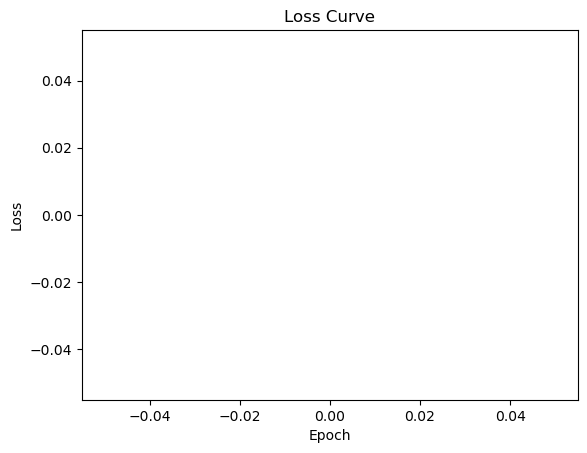

Epoch: 1, Loss: 1685.342977487039 + 0.0im
Epoch: 2, Loss: 1444.041981253328 + 0.0im
Epoch: 3, Loss: 1251.7912155832762 + 0.0im
Epoch: 4, Loss: 1082.327378826587 + 0.0im
Epoch: 5, Loss: 922.2234432889089 + 0.0im
Epoch: 6, Loss: 790.6841255576797 + 0.0im
Epoch: 7, Loss: 668.6337288968462 + 0.0im
Epoch: 8, Loss: 568.6088438913087 + 0.0im
Epoch: 9, Loss: 475.35035997729716 + 0.0im
Epoch: 10, Loss: 401.07112893185405 + 0.0im
Epoch: 11, Loss: 335.10120911161346 + 0.0im
Epoch: 12, Loss: 278.29385895953857 + 0.0im
Epoch: 13, Loss: 229.32575212527968 + 0.0im
Epoch: 14, Loss: 190.47249146894163 + 0.0im
Epoch: 15, Loss: 156.37037834287162 + 0.0im
Epoch: 16, Loss: 127.20046279578409 + 0.0im
Epoch: 17, Loss: 104.35001104426432 + 0.0im
Epoch: 18, Loss: 85.36096067548412 + 0.0im
Epoch: 19, Loss: 68.58594999239294 + 0.0im
Epoch: 20, Loss: 54.694460473534065 + 0.0im
Epoch: 21, Loss: 43.6191657911827 + 0.0im
Epoch: 22, Loss: 34.421431156460066 + 0.0im
Epoch: 23, Loss: 27.32157841536447 + 0.0im
Epoch: 24

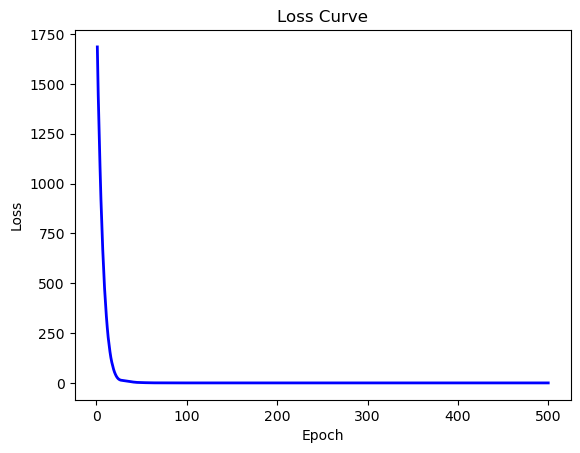

In [7]:
train(opt,layers,x,t,D,epochs=500)